# CS-781 Capstone — Phase 2: Legal NER with the Phase-1 Encoder–Decoder

This notebook adapts the **Phase-1 Legal Encoder–Decoder** (`LegalSeq2SeqLM`: RMSNorm, T5-style relative
position bias, gated-GELU FFN, tied embeddings, custom BPE tokenizer) to **L-NER**: predict
`[start_char, end_char, label]` spans for 12 legal entity types. The metric is strict Macro-F1.

**Why the encoder?** NER is a labelling task, so each token benefits from seeing context on both sides.
The Phase-1 *encoder* is bidirectional, so the main experiments put a token-classification head on it. The
causal *decoder* is not thrown away. Experiment 7 tests an **encoder + decoder fusion head**, which lets you
answer "does the decoder add anything for NER?" in the report.

| # | Experiment | Technique (brief §8.2.1) | Starts from |
|---|---|---|---|
| 1 | `exp1_full_ft` | Full fine-tuning | Phase-1 encoder |
| 2 | `exp2_partial_ft` | Partial / layer-wise FT (bottom layers + embeddings frozen) | Phase-1 encoder |
| 3 | `exp3_lora` | LoRA [3] | Phase-1 encoder |
| 4 | `exp4_lorma` | **LoRMA⁺ [12] (compulsory)** — multiplicative low-rank update | Phase-1 encoder |
| 5 | `exp5_adapters` | Houlsby bottleneck adapters [6] | Phase-1 encoder |
| 6 | `exp6_kd` | **Knowledge distillation (mandatory)**: 9-layer FT teacher → 5-layer student | Phase-1 encoder (layer-dropped) |
| 7 | `exp7_encdec_lorma` | *(optional extra)* LoRMA⁺ on encoder **and** decoder, fusion head | full Phase-1 seq2seq |

**What's different from the GQLA Phase-2 notebook:**
* **LoRMA is the real formulation from the paper.** The paper's update is multiplicative, $W=(I+\tfrac{\alpha}{r}BA)\,W_0$
  (LoRMA⁺, additive identity inflation), not a gated LoRA. It is computed as $h=W_0x$, then $y=h+\tfrac{\alpha}{r}B(Ah)$.
* **Sliding windows with overlap**, so no entity is cut at a chunk edge. Token probabilities from overlapping windows are merged, with tokens near the centre of a window weighted more.
* **Exact evaluation against the gold spans.** The GQLA notebook compared predictions with *BIO-reconstructed* spans, which hides alignment errors. This notebook also prints the
  **alignment ceiling**: the best F1 achievable with word-level BIO.
* **BIO-constrained Viterbi decoding**, compared against plain argmax (a span-decoding ablation).
* Results, histories and checkpoints are saved to Drive after every experiment, so a Colab disconnect doesn't lose them.

> **Scope:** the brief wants experiments across *all four* Phase-1 architectures. This notebook covers the
> encoder–decoder architecture; combine its runs with your GQLA (and other) Phase-2 runs for the report.

## 0. Setup

In [ ]:
!pip -q install huggingface_hub

In [ ]:
import os, re, json, math, time, random, zipfile, gc, copy, unicodedata
from collections import defaultdict, Counter
from functools import partial

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_everything()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)
    IN_COLAB = True
except Exception:
    IN_COLAB = False

Device: cuda | Tesla T4
Mounted at /content/drive


## 1. Config
Paths default to the layout of your Phase-1 encoder–decoder notebook
(`Phase1_Pretraining/phase1_encoder_decoder/...`). Change them if you moved anything.

**HF token:** don't hard-code it. In Colab, add it under 🔑 *Secrets* as `HF_TOKEN`, or set it as an env variable.

In [ ]:
import shutil
DRIVE_ROOT    = "/content/drive/MyDrive/Phase1_Pretraining"
P1_WORK_DIR   = os.path.join(DRIVE_ROOT, "phase1_encoder_decoder")
TOKENIZER_PATH = os.path.join(P1_WORK_DIR, "final_bpe_en.json")
P1_CKPT_PATH  = os.path.join(P1_WORK_DIR, "checkpoints", "encoder_decoder_best.pt")

PHASE2_DIR    = os.path.join(DRIVE_ROOT, "phase2_lner_encoder_decoder")
CKPT_DIR      = os.path.join(PHASE2_DIR, "checkpoints")
SUB_DIR       = os.path.join(PHASE2_DIR, "submissions")
RESULTS_PATH  = os.path.join(PHASE2_DIR, "results.json")
# ---- one-time repair: an earlier run created a FOLDER named final_bpe_en.json next to the real tokenizer file
#      (Drive allows a file and a folder with the same name). Remove the folder if it holds no files.
if os.path.isdir(TOKENIZER_PATH):
    stray = [os.path.join(r, f) for r, _, fs in os.walk(TOKENIZER_PATH) for f in fs]
    if stray:
        raise RuntimeError(f"{TOKENIZER_PATH} is a folder that contains files {stray[:5]} - move them out, then delete it in Drive")
    shutil.rmtree(TOKENIZER_PATH)
    print("removed stray folder", TOKENIZER_PATH, "- if the file still does not show up, run drive.flush_and_unmount() and remount")
if not os.path.isfile(TOKENIZER_PATH):
    raise FileNotFoundError(f"Phase-1 tokenizer file not found: {TOKENIZER_PATH}")
if not os.path.isfile(P1_CKPT_PATH):
    raise FileNotFoundError(f"Phase-1 checkpoint not found: {P1_CKPT_PATH}")

for d in (PHASE2_DIR, CKPT_DIR, SUB_DIR):
    os.makedirs(d, exist_ok=True)

LOCAL_DATA_DIR = None     # e.g. "/content/Phase_2_LNER" if you already have the files; else HF download
HF_REPO = "Exploration-Lab/CS-781-Capstone"
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        pass

# ---- data / windows ----
DEV_STRATEGY   = "fold2"  # "fold2": train=fold1, dev=fold2 (cross-fold, like the GQLA nb)
                          # "holdout": pool fold1+fold2, hold out DEV_FRAC of documents
DEV_FRAC       = 0.15
MAX_LEN        = 512      # encoder window in BPE tokens (Phase-1 MAX_ENC_LEN)
STRIDE         = 384      # window step; MAX_LEN-STRIDE tokens of overlap
LABEL_ALL_SUBTOKENS = True  # True: continuation sub-tokens get I-X; False: -100 (first-sub-token only)

# ---- training ----
BATCH_SIZE     = 8
GRAD_ACCUM     = 1
EPOCHS         = 6
PATIENCE       = 2        # early stopping on dev strict Macro-F1
WARMUP_FRAC    = 0.06
WEIGHT_DECAY   = 0.01
FT_DROPOUT     = 0.1
HEAD_LR_MULT   = 10.0     # task head learns faster than the pretrained body
USE_AMP        = DEVICE.type == "cuda"
CLASS_WEIGHTING = None    # None | "sqrt_inv" (class-imbalance ablation)
O_WEIGHT       = 1.0      # weight for the 'O' class when CLASS_WEIGHTING is set
DECODE         = "viterbi"  # "viterbi" (BIO-constrained) | "argmax"
LOG_EVERY      = 50

## 2. Phase-1 BPE tokenizer (inference part, identical to Phase 1)
Words come from `WORD_RE` on the **raw** text, so every word keeps its exact character span. For encoding
only, each word goes through the same character normalisation used in Phase-1 pretraining (curly quotes and dashes become ASCII, plus NFKC). That way the model sees familiar ids, while the offsets still point into the original text.

In [ ]:
import os
# This will search for final_bpe_en.json in your Drive to find its exact path
for root, dirs, files in os.walk("/content/drive/MyDrive/"):
    if "final_bpe_en.json" in files:
        print("Found Tokenizer at:", os.path.join(root, "final_bpe_en.json"))

Found Tokenizer at: /content/drive/MyDrive/Phase1_Pretraining/phase1_encoder_decoder/final_bpe_en.json


In [ ]:
import heapq

WORD_RE = re.compile(r"\w+|[^\w\s]", re.UNICODE)   # MUST match Phase 1

class BPETokenizer:
    _HEAP_THRESHOLD = 24
    _CACHE_LIMIT = 500_000

    def __init__(self, vocab_size, end_marker="</w>", reserved_tokens=None):
        self.vocab_size = vocab_size
        self.end_marker = end_marker
        self.reserved_tokens = reserved_tokens or ["<pad>", "<unk>", "<s>", "</s>"]
        self.itos = list(self.reserved_tokens)
        self.stoi = {t: i for i, t in enumerate(self.reserved_tokens)}
        self.merges = {}
        self._ready = False
        self._cache = {}

    @staticmethod
    def from_json(path):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        tok = BPETokenizer(data["vocab_size"], data.get("end_marker", "</w>"),
                           data.get("reserved_tokens", ["<pad>", "<unk>", "<s>", "</s>"]))
        tok.itos = data["itos"]; tok.stoi = data["stoi"]
        tok.merges = {tuple(p): r for p, r in data["merges"]}
        return tok

    def _prepare_inference(self):
        if self._ready:
            return
        self._byte_ids = [self.stoi[bytes([b]).decode("latin-1")] for b in range(256)]
        self._first_merge_id = len(self.itos) - len(self.merges)
        self._end_id = self.stoi.get(self.end_marker, self.stoi["<unk>"])
        base = self._first_merge_id
        for (a, b), r in self.merges.items():
            if self.itos[base + r] != self.itos[a] + self.itos[b]:
                raise ValueError("Merge/vocab mismatch: cannot infer merge ids from ranks.")
        self._M = len(self.itos)
        self._ranks = {a * self._M + b: r for (a, b), r in self.merges.items()}
        self._cache = {}
        self._ready = True

    def _merge_small(self, ids):
        get, M, base = self._ranks.get, self._M, self._first_merge_id
        while len(ids) > 1:
            best, best_i = None, -1
            for i in range(len(ids) - 1):
                r = get(ids[i] * M + ids[i + 1])
                if r is not None and (best is None or r < best):
                    best, best_i = r, i
            if best is None:
                break
            a, b, new = ids[best_i], ids[best_i + 1], base + best
            out, i, n = [], 0, len(ids)
            while i < n:
                if i < n - 1 and ids[i] == a and ids[i + 1] == b:
                    out.append(new); i += 2
                else:
                    out.append(ids[i]); i += 1
            ids = out
        return ids

    def _merge_heap(self, ids):
        get, M, base = self._ranks.get, self._M, self._first_merge_id
        n = len(ids)
        nxt = list(range(1, n + 1)); nxt[-1] = -1
        prv = list(range(-1, n - 1))
        alive = [True] * n
        heap = [(r, i) for i in range(n - 1) if (r := get(ids[i] * M + ids[i + 1])) is not None]
        heapq.heapify(heap)
        while heap:
            r, i = heapq.heappop(heap)
            if not alive[i]:
                continue
            j = nxt[i]
            if j == -1 or get(ids[i] * M + ids[j]) != r:
                continue
            ids[i] = base + r
            alive[j] = False
            k = nxt[j]; nxt[i] = k
            if k != -1:
                prv[k] = i
            p = prv[i]
            if p != -1 and (r2 := get(ids[p] * M + ids[i])) is not None:
                heapq.heappush(heap, (r2, p))
            if k != -1 and (r2 := get(ids[i] * M + ids[k])) is not None:
                heapq.heappush(heap, (r2, i))
        return [ids[i] for i in range(n) if alive[i]]

    def _bpe_word(self, word):
        self._prepare_inference()
        hit = self._cache.get(word)
        if hit is not None:
            return hit
        ids = [self._byte_ids[b] for b in word.encode("utf-8")] + [self._end_id]
        ids = self._merge_small(ids) if len(ids) <= self._HEAP_THRESHOLD else self._merge_heap(ids)
        result = tuple(ids)
        if len(self._cache) < self._CACHE_LIMIT:
            self._cache[word] = result
        return result

    def encode(self, text, add_special_tokens=True):
        self._prepare_inference()
        out = [self.stoi["<s>"]] if add_special_tokens else []
        for w in WORD_RE.findall(text):
            out.extend(self._bpe_word(w))
        if add_special_tokens:
            out.append(self.stoi["</s>"])
        return out


# Same character map as Phase-1 normalize_text(); applied per word (offsets stay in raw text)
_CHAR_MAP = {ord(c): None for c in ("​‌‍‎‏⁠﻿­"
                                    "‪‫‬‭‮")}
_CHAR_MAP.update({ord(c): "'" for c in "‘’‚‛′ʼ"})
_CHAR_MAP.update({ord(c): '"' for c in "“”„‟″"})
_CHAR_MAP.update({ord(c): "-" for c in "‐‑‒–—―−"})

def normalize_word(w):
    w2 = w.translate(_CHAR_MAP)
    if not w2.isascii():
        w2 = unicodedata.normalize("NFKC", w2)
    w2 = "".join(w2.split())           # NFKC can create spaces (rare)
    return w2 if w2 else w             # never drop a word: keep it so it gets tokens

tokenizer = BPETokenizer.from_json(TOKENIZER_PATH)    # must be the Phase-1 tokenizer the checkpoint was trained with
tokenizer._prepare_inference()
PAD_ID, BOS_ID, EOS_ID = tokenizer.stoi["<pad>"], tokenizer.stoi["<s>"], tokenizer.stoi["</s>"]
VOCAB_SIZE = len(tokenizer.itos)
print(f"Tokenizer: vocab={VOCAB_SIZE:,} | PAD={PAD_ID} BOS={BOS_ID} EOS={EOS_ID}")

Tokenizer: vocab=32,768 | PAD=0 BOS=2 EOS=3


## 3. Phase-1 Encoder–Decoder architecture (copied unchanged so the checkpoint loads exactly)

In [ ]:
class RMSNorm(nn.Module):
    def __init__(self, d_model, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(d_model))
        self.eps = eps
    def forward(self, x):
        var = x.pow(2).mean(-1, keepdim=True)
        return self.weight * (x * torch.rsqrt(var + self.eps))


class RelativePositionBias(nn.Module):
    def __init__(self, num_heads, num_buckets=32, max_distance=128, bidirectional=True):
        super().__init__()
        self.num_buckets, self.max_distance, self.bidirectional = num_buckets, max_distance, bidirectional
        self.embedding = nn.Embedding(num_buckets, num_heads)

    @staticmethod
    def _bucket(relative_position, bidirectional, num_buckets, max_distance):
        ret = 0
        n = -relative_position
        if bidirectional:
            num_buckets //= 2
            ret += (n < 0).to(torch.long) * num_buckets
            n = torch.abs(n)
        else:
            n = torch.clamp(n, min=0)
        max_exact = num_buckets // 2
        is_small = n < max_exact
        val_if_large = max_exact + (torch.log(n.float() / max_exact + 1e-6)
                                    / math.log(max_distance / max_exact)
                                    * (num_buckets - max_exact)).to(torch.long)
        val_if_large = torch.clamp(val_if_large, max=num_buckets - 1)
        return ret + torch.where(is_small, n, val_if_large)

    def forward(self, q_len, k_len, device):
        q_pos = torch.arange(q_len, device=device)[:, None]
        k_pos = torch.arange(k_len, device=device)[None, :]
        bucket = self._bucket(k_pos - q_pos, self.bidirectional, self.num_buckets, self.max_distance)
        return self.embedding(bucket).permute(2, 0, 1).unsqueeze(0)


class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0
        self.num_heads, self.d_head = num_heads, d_model // num_heads
        self.q = nn.Linear(d_model, d_model, bias=False)
        self.k = nn.Linear(d_model, d_model, bias=False)
        self.v = nn.Linear(d_model, d_model, bias=False)
        self.o = nn.Linear(d_model, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x_q, x_kv, mask=None, position_bias=None):
        B, Lq, D = x_q.shape
        Lk = x_kv.shape[1]
        q = self.q(x_q).view(B, Lq, self.num_heads, self.d_head).transpose(1, 2)
        k = self.k(x_kv).view(B, Lk, self.num_heads, self.d_head).transpose(1, 2)
        v = self.v(x_kv).view(B, Lk, self.num_heads, self.d_head).transpose(1, 2)
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.d_head)
        if position_bias is not None:
            scores = scores + position_bias
        if mask is not None:
            scores = scores.masked_fill(mask == 0, float("-inf"))
        attn = self.dropout(torch.softmax(scores, dim=-1))
        out = torch.matmul(attn, v).transpose(1, 2).contiguous().view(B, Lq, D)
        return self.o(out)


class GatedFeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.wi_0 = nn.Linear(d_model, d_ff, bias=False)
        self.wi_1 = nn.Linear(d_model, d_ff, bias=False)
        self.wo = nn.Linear(d_ff, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.act = nn.GELU()
    def forward(self, x):
        return self.wo(self.dropout(self.act(self.wi_0(x)) * self.wi_1(x)))


class EncoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.ln1 = RMSNorm(d_model); self.self_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.ln2 = RMSNorm(d_model); self.ff = GatedFeedForward(d_model, d_ff, dropout)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x, mask, position_bias):
        h = self.ln1(x)
        x = x + self.dropout(self.self_attn(h, h, mask, position_bias))
        return x + self.dropout(self.ff(self.ln2(x)))


class DecoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.ln1 = RMSNorm(d_model); self.self_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.ln2 = RMSNorm(d_model); self.cross_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.ln3 = RMSNorm(d_model); self.ff = GatedFeedForward(d_model, d_ff, dropout)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x, enc_out, self_mask, cross_mask, self_pos_bias):
        h = self.ln1(x)
        x = x + self.dropout(self.self_attn(h, h, self_mask, self_pos_bias))
        h = self.ln2(x)
        x = x + self.dropout(self.cross_attn(h, enc_out, cross_mask, None))
        return x + self.dropout(self.ff(self.ln3(x)))


class Encoder(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, num_layers, dropout=0.1):
        super().__init__()
        self.layers = nn.ModuleList([EncoderLayer(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)])
        self.pos_bias = RelativePositionBias(num_heads, bidirectional=True)
        self.final_ln = RMSNorm(d_model)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x, attention_mask):
        L = x.shape[1]
        pos_bias = self.pos_bias(L, L, x.device)
        mask = attention_mask[:, None, None, :]
        x = self.dropout(x)
        for layer in self.layers:
            x = layer(x, mask, pos_bias)
        return self.final_ln(x)


class Decoder(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, num_layers, dropout=0.1):
        super().__init__()
        self.layers = nn.ModuleList([DecoderLayer(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)])
        self.pos_bias = RelativePositionBias(num_heads, bidirectional=False)
        self.final_ln = RMSNorm(d_model)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x, enc_out, self_attention_mask, cross_attention_mask):
        L = x.shape[1]
        causal = torch.tril(torch.ones(L, L, device=x.device, dtype=torch.bool))
        pad = self_attention_mask[:, None, None, :].bool()
        self_mask = (causal[None, None] & pad).float()
        cross_mask = cross_attention_mask[:, None, None, :]
        pos_bias = self.pos_bias(L, L, x.device)
        x = self.dropout(x)
        for layer in self.layers:
            x = layer(x, enc_out, self_mask, cross_mask, pos_bias)
        return self.final_ln(x)


class LegalSeq2SeqLM(nn.Module):
    def __init__(self, vocab_size, d_model=512, num_heads=16, d_ff=2048,
                 num_encoder_layers=9, num_decoder_layers=9, dropout=0.1, pad_id=0):
        super().__init__()
        self.shared_embed = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.encoder = Encoder(d_model, num_heads, d_ff, num_encoder_layers, dropout)
        self.decoder = Decoder(d_model, num_heads, d_ff, num_decoder_layers, dropout)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.lm_head.weight = self.shared_embed.weight
    def forward(self, input_ids, attention_mask, decoder_input_ids, decoder_attention_mask):
        enc_out = self.encoder(self.shared_embed(input_ids), attention_mask)
        dec_out = self.decoder(self.shared_embed(decoder_input_ids), enc_out, decoder_attention_mask, attention_mask)
        return self.lm_head(dec_out)


P1_DEFAULT_CFG = dict(d_model=512, num_heads=16, d_ff=2048, num_encoder_layers=9, num_decoder_layers=9)
_P1_CACHE = {}

def load_phase1_seq2seq(ckpt_path=P1_CKPT_PATH, dropout=FT_DROPOUT):
    """Fresh LegalSeq2SeqLM with Phase-1 weights. State dict is cached on CPU so every
    experiment starts from exactly the same pretrained weights without re-reading Drive."""
    if ckpt_path not in _P1_CACHE:
        if not os.path.exists(ckpt_path):
            raise FileNotFoundError(f"Phase-1 checkpoint not found: {ckpt_path}")
        ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        sd = ckpt.get("model_state_dict", ckpt)
        sd = {k.replace("_orig_mod.", ""): v for k, v in sd.items()}
        cfg = dict(P1_DEFAULT_CFG); cfg.update({k: v for k, v in (ckpt.get("model_config") or {}).items()
                                                  if k in P1_DEFAULT_CFG})
        print(f"Phase-1 checkpoint: step={ckpt.get('global_step')} best_val_loss={ckpt.get('best_val_loss')}")
        print("Phase-1 config:", cfg)
        _P1_CACHE[ckpt_path] = (sd, cfg)
    sd, cfg = _P1_CACHE[ckpt_path]
    model = LegalSeq2SeqLM(VOCAB_SIZE, dropout=dropout, pad_id=PAD_ID, **cfg)
    missing, unexpected = model.load_state_dict(sd, strict=False)
    missing = [m for m in missing if m != "lm_head.weight"]      # tied to shared_embed
    if missing or unexpected:
        print(f"  WARNING missing={missing[:5]} unexpected={unexpected[:5]}")
    assert model.shared_embed.num_embeddings == VOCAB_SIZE, "tokenizer / checkpoint vocab mismatch"
    return model

_m = load_phase1_seq2seq()
print(f"Phase-1 seq2seq params: {sum(p.numel() for p in _m.parameters())/1e6:.1f}M "
      f"(encoder+embed: {(sum(p.numel() for p in _m.encoder.parameters()) + _m.shared_embed.weight.numel())/1e6:.1f}M)")
P1_CFG = _P1_CACHE[P1_CKPT_PATH][1]
del _m

Phase-1 checkpoint: step=11200 best_val_loss=4.871949663513102
Phase-1 config: {'d_model': 512, 'num_heads': 16, 'd_ff': 2048, 'num_encoder_layers': 9, 'num_decoder_layers': 9}
Phase-1 seq2seq params: 101.7M (encoder+embed: 54.5M)


## 4. Phase-2 data

In [ ]:
def get_file(rel):
    if LOCAL_DATA_DIR:
        return os.path.join(LOCAL_DATA_DIR, rel.split("/", 1)[1])
    from huggingface_hub import hf_hub_download
    return hf_hub_download(repo_id=HF_REPO, filename=rel, repo_type="dataset", token=HF_TOKEN)

def read_json(p):
    with open(p, encoding="utf-8") as f:
        return json.load(f)

paths = {k: get_file(v) for k, v in {
    "f1_text": "Phase_2_LNER/Train/fold1-text.json", "f1_gold": "Phase_2_LNER/Train/fold1-gold.json",
    "f2_text": "Phase_2_LNER/Train/fold2-text.json", "f2_gold": "Phase_2_LNER/Train/fold2-gold.json",
    "labels":  "Phase_2_LNER/Train/labels.txt",     "f3_text": "Phase_2_LNER/Test/fold3-text.json"}.items()}

with open(paths["labels"], encoding="utf-8") as f:
    ENTITY_LABELS = [l.strip() for l in f if l.strip() and l.strip() != "O"]
print("Entity labels:", ENTITY_LABELS)

def _parse_entity(e):
    """Accepts [s, e, label(, text)] lists or {'start','end','label'} dicts."""
    if isinstance(e, dict):
        s = e.get("start", e.get("start_char")); t = e.get("end", e.get("end_char"))
        return int(s), int(t), str(e.get("label", e.get("type")))
    return int(e[0]), int(e[1]), str(e[2])

def load_fold(text_path, gold_path=None):
    texts = read_json(text_path)
    if isinstance(texts, list):   # tolerate [{'id':..,'text':..}]
        texts = {str(d["id"]): d["text"] for d in texts}
    golds = read_json(gold_path) if gold_path else {}
    docs = {}
    for doc_id, text in texts.items():
        ents = [_parse_entity(e) for e in golds.get(doc_id, [])] if gold_path else None
        docs[str(doc_id)] = (text, ents)
    return docs

fold1 = load_fold(paths["f1_text"], paths["f1_gold"])
fold2 = load_fold(paths["f2_text"], paths["f2_gold"])
test_raw = load_fold(paths["f3_text"])

if DEV_STRATEGY == "fold2":
    train_raw, dev_raw = fold1, fold2
else:
    pool = {**fold1, **fold2}
    ids = sorted(pool); random.Random(SEED).shuffle(ids)
    n_dev = max(1, int(len(ids) * DEV_FRAC))
    dev_raw = {i: pool[i] for i in ids[:n_dev]}
    train_raw = {i: pool[i] for i in ids[n_dev:]}
ALL_LABELED_RAW = {**fold1, **fold2}

def corpus_stats(name, docs):
    lab = Counter(l for _, ents in docs.values() for (_, _, l) in (ents or []))
    chars = [len(t) for t, _ in docs.values()]
    print(f"{name:6s}: {len(docs):4d} docs | chars/doc mean={np.mean(chars):,.0f} max={max(chars):,} "
          f"| entities={sum(lab.values()):,}")
    return lab

lab_train = corpus_stats("train", train_raw); corpus_stats("dev", dev_raw); corpus_stats("test", test_raw)
print("\nTrain label distribution (class imbalance):")
for l in ENTITY_LABELS:
    print(f"  {l:10s} {lab_train.get(l, 0):6d}")
unknown = set(lab_train) - set(ENTITY_LABELS)
if unknown:
    print("WARNING: gold labels not in labels.txt (ignored):", unknown)

fold1-text.json:   0%|          | 0.00/1.11M [00:00<?, ?B/s]

fold1-gold.json:   0%|          | 0.00/461k [00:00<?, ?B/s]

fold2-text.json:   0%|          | 0.00/1.12M [00:00<?, ?B/s]

fold2-gold.json:   0%|          | 0.00/475k [00:00<?, ?B/s]

labels.txt:   0%|          | 0.00/71.0 [00:00<?, ?B/s]

fold3-text.json:   0%|          | 0.00/1.19M [00:00<?, ?B/s]

Entity labels: ['APP', 'RESP', 'A.COUNSEL', 'R.COUNSEL', 'JUDGE', 'WIT', 'AUTH', 'COURT', 'STAT', 'PREC', 'DATE', 'CASENO']
train :   35 docs | chars/doc mean=31,360 max=106,947 | entities=4,120
dev   :   35 docs | chars/doc mean=31,887 max=114,044 | entities=4,273
test  :   35 docs | chars/doc mean=33,509 max=97,103 | entities=0

Train label distribution (class imbalance):
  APP           207
  RESP          191
  A.COUNSEL      70
  R.COUNSEL      87
  JUDGE         123
  WIT            67
  AUTH          535
  COURT         455
  STAT          525
  PREC          624
  DATE          813
  CASENO        423


## 5. Char ↔ word ↔ BPE alignment, BIO labels, and the alignment ceiling
Each `WORD_RE` word keeps its `(start, end)` in the raw text. A word gets `B-X`/`I-X` if it overlaps entity X. Decoding
joins consecutive tagged words and returns `(first_word.start, last_word.end)`. **If a gold boundary falls inside a
word, word-level BIO cannot reproduce it.** The ceiling printed below measures how often that happens. Quote it in the
"span vs token modelling / char-offset correctness" part of your analysis.

In [ ]:
BIO_TAGS = ["O"] + [f"{p}-{l}" for l in ENTITY_LABELS for p in ("B", "I")]
tag2id = {t: i for i, t in enumerate(BIO_TAGS)}
id2tag = {i: t for t, i in tag2id.items()}
NUM_TAGS = len(BIO_TAGS)

def word_split(text):
    return [(m.start(), m.end()) for m in WORD_RE.finditer(text)]

def encode_words(text, word_spans):
    """BPE ids for each word (encoded from the normalised word, offsets from raw text)."""
    token_ids, tok2word, word_first_tok = [], [], []
    for wi, (s, e) in enumerate(word_spans):
        ids = tokenizer._bpe_word(normalize_word(text[s:e]))
        word_first_tok.append(len(token_ids))
        token_ids.extend(ids); tok2word.extend([wi] * len(ids))
    return token_ids, tok2word, word_first_tok

def assign_word_tags(word_spans, entities, stats=None):
    tags = ["O"] * len(word_spans)
    starts = np.array([s for s, _ in word_spans]) if word_spans else np.zeros(0, int)
    ends = np.array([e for _, e in word_spans]) if word_spans else np.zeros(0, int)
    # longest-first at equal start; skip entities that overlap an already-tagged one (nested/overlapping)
    for (es, ee, el) in sorted(entities, key=lambda x: (x[0], -(x[1] - x[0]))):
        if f"B-{el}" not in tag2id:
            if stats is not None: stats["unknown_label"] += 1
            continue
        idx = np.nonzero((ends > es) & (starts < ee))[0]
        if len(idx) == 0:
            if stats is not None: stats["no_word"] += 1
            continue
        if any(tags[i] != "O" for i in idx):
            if stats is not None: stats["overlap_skipped"] += 1
            continue
        for k, i in enumerate(idx):
            tags[i] = ("B-" if k == 0 else "I-") + el
    return tags

def tags_to_spans(word_spans, tags):
    """BIO word tags -> set of (start, end, label). A stray I-X starts a new span (lenient)."""
    spans, cur = [], None
    for (ws, we), tag in zip(word_spans, tags):
        if tag == "O":
            if cur: spans.append(tuple(cur)); cur = None
            continue
        p, lab = tag.split("-", 1)
        if p == "B" or cur is None or cur[2] != lab:
            if cur: spans.append(tuple(cur))
            cur = [ws, we, lab]
        else:
            cur[1] = we
    if cur: spans.append(tuple(cur))
    return spans


class PreparedDoc:
    __slots__ = ("doc_id", "text", "word_spans", "token_ids", "tok2word", "word_first_tok", "word_tags", "gold")

def prepare(docs_raw, name=""):
    out, st = {}, Counter()
    for doc_id, (text, ents) in docs_raw.items():
        d = PreparedDoc()
        d.doc_id, d.text = doc_id, text
        d.word_spans = word_split(text)
        d.token_ids, d.tok2word, d.word_first_tok = encode_words(text, d.word_spans)
        d.gold = None if ents is None else {e for e in ents if e[2] in ENTITY_LABELS}
        d.word_tags = assign_word_tags(d.word_spans, ents, st) if ents is not None else None
        out[doc_id] = d
    n_tok = [len(d.token_ids) for d in out.values()]
    print(f"{name:6s}: tokens/doc mean={np.mean(n_tok):,.0f} max={max(n_tok):,} | "
          f"words/token={sum(len(d.word_spans) for d in out.values())/max(sum(n_tok),1):.2f} | {dict(st)}")
    return out

train_docs = prepare(train_raw, "train")
dev_docs   = prepare(dev_raw, "dev")
test_docs  = prepare(test_raw, "test")

train : tokens/doc mean=6,656 max=22,022 | words/token=0.96 | {}
dev   : tokens/doc mean=6,656 max=23,868 | words/token=0.97 | {}
test  : tokens/doc mean=7,107 max=20,771 | words/token=0.96 | {}


In [ ]:
def strict_prf(pred_by_doc, gold_by_doc, labels=None):
    """Strict span+label match, macro-averaged over the official labels (mirrors the Codabench metric)."""
    labels = labels or ENTITY_LABELS
    c = {l: Counter() for l in labels}
    for doc_id, gold in gold_by_doc.items():
        pred = set(pred_by_doc.get(doc_id, ()))
        gold = set(gold)
        for sp in pred:
            if sp[2] in c: c[sp[2]]["tp" if sp in gold else "fp"] += 1
        for sp in gold - pred:
            if sp[2] in c: c[sp[2]]["fn"] += 1
    per = {}
    for l in labels:
        tp, fp, fn = c[l]["tp"], c[l]["fp"], c[l]["fn"]
        p = tp / (tp + fp) if tp + fp else 0.0
        r = tp / (tp + fn) if tp + fn else 0.0
        per[l] = dict(p=p, r=r, f1=2 * p * r / (p + r) if p + r else 0.0, support=tp + fn)
    # average over labels that occur in gold or in predictions (a label absent from both is undefined);
    # on the real folds all 12 labels occur, so this equals the plain 12-label macro average
    active = [l for l in labels if per[l]["support"] or c[l]["fp"]] or labels
    P = np.mean([per[l]["p"] for l in active]); R = np.mean([per[l]["r"] for l in active])
    Fm = np.mean([per[l]["f1"] for l in active])
    return dict(p=float(P), r=float(R), f1=float(Fm), per_label=per)

# ---- Alignment ceiling: decode the *gold* BIO tags and score against the gold char spans ----
for name, docs in (("train", train_docs), ("dev", dev_docs)):
    oracle = {i: tags_to_spans(d.word_spans, d.word_tags) for i, d in docs.items()}
    res = strict_prf(oracle, {i: d.gold for i, d in docs.items()})
    print(f"[{name}] word-BIO alignment ceiling: strict Macro-F1 = {res['f1']:.4f}")
    worst = sorted(res["per_label"].items(), key=lambda kv: kv[1]["f1"])[:3]
    print("   lowest-ceiling labels:", [(l, round(v['f1'], 3)) for l, v in worst])

# show a few gold spans that word-BIO cannot reproduce (useful for the report)
bad = []
for d in dev_docs.values():
    rec = set(tags_to_spans(d.word_spans, d.word_tags))
    for g in d.gold:
        if g not in rec and len(bad) < 8:
            bad.append((d.doc_id, g, repr(d.text[max(0, g[0]-15):g[1]+15])))
for b in bad: print("  unreachable:", b)

[train] word-BIO alignment ceiling: strict Macro-F1 = 0.9876
   lowest-ceiling labels: [('PREC', 0.931), ('APP', 0.981), ('AUTH', 0.983)]
[dev] word-BIO alignment ceiling: strict Macro-F1 = 0.9877
   lowest-ceiling labels: [('PREC', 0.927), ('COURT', 0.978), ('STAT', 0.982)]
  unreachable: ('76640285', (18, 41, 'COURT'), "'ORTABLE IN THE SUPREME COURT OF INDIA CRIMINAL APPELL'")
  unreachable: ('58138931', (17450, 17453, 'STAT'), "'Under Order XXICPC, the various s'")
  unreachable: ('58138931', (10277, 10336, 'PREC'), "') 1 SCC 6 iii. Asgar & Others v Mohan Verma & Others 2019 (3) CLJ 16 (SC) iv Babulal v Ra'")
  unreachable: ('58138931', (24886, 24896, 'DATE'), "' judgment dated24.12.1999 and it can be '")
  unreachable: ('58138931', (5289, 5304, 'COURT'), "'ed by both the Appellate Courts. 4. Consideri'")
  unreachable: ('108594766', (24748, 24759, 'PREC'), "' this Court in Sarla Verma1 as affirmed i'")
  unreachable: ('108594766', (26779, 26791, 'PREC'), "'he judgment in Pranay Set

## 6. Sliding-window dataset
Each document is split into overlapping windows of `MAX_LEN-1` BPE tokens plus a trailing `</s>`, matching how Phase-1 encoder inputs ended.
Every window records its token offset, so predictions can be merged back into the document.

In [ ]:
def token_labels(d):
    labs, prev = [], None
    for ti, wi in enumerate(d.tok2word):
        t = d.word_tags[wi]
        if wi == prev:                         # continuation sub-token
            if not LABEL_ALL_SUBTOKENS: labs.append(-100); continue
            t = "O" if t == "O" else "I-" + t.split("-", 1)[1]
        labs.append(tag2id[t]); prev = wi
    return labs

def make_windows(docs, with_labels=True, max_len=MAX_LEN, stride=STRIDE):
    body = max_len - 1
    ex = []
    for doc_id, d in docs.items():
        labs = token_labels(d) if (with_labels and d.word_tags is not None) else None
        n = len(d.token_ids)
        starts = list(range(0, max(n - body, 0) + 1, stride))
        if starts[-1] + body < n:
            starts.append(n - body)
        for s in starts:
            e = min(s + body, n)
            if e <= s: continue
            ex.append(dict(doc_id=doc_id, start=s,
                           input_ids=d.token_ids[s:e] + [EOS_ID],
                           labels=(labs[s:e] + [-100]) if labs is not None else None))
    return ex

class WindowDataset(Dataset):
    def __init__(self, examples): self.ex = examples
    def __len__(self): return len(self.ex)
    def __getitem__(self, i): return self.ex[i]

def collate(batch):
    L = max(len(b["input_ids"]) for b in batch)
    ids = torch.full((len(batch), L), PAD_ID, dtype=torch.long)
    att = torch.zeros((len(batch), L), dtype=torch.long)
    lab = torch.full((len(batch), L), -100, dtype=torch.long)
    for i, b in enumerate(batch):
        n = len(b["input_ids"])
        ids[i, :n] = torch.tensor(b["input_ids"]); att[i, :n] = 1
        if b["labels"] is not None:
            lab[i, :n] = torch.tensor(b["labels"])
    return dict(input_ids=ids, attention_mask=att, labels=lab,
                doc_id=[b["doc_id"] for b in batch], start=[b["start"] for b in batch],
                n=[len(b["input_ids"]) for b in batch])

def make_loader(docs, shuffle, with_labels=True, bs=BATCH_SIZE):
    return DataLoader(WindowDataset(make_windows(docs, with_labels)), batch_size=bs, shuffle=shuffle,
                      collate_fn=collate, num_workers=0, pin_memory=DEVICE.type == "cuda")

train_loader = make_loader(train_docs, shuffle=True)
dev_loader   = make_loader(dev_docs, shuffle=False)
test_loader  = make_loader(test_docs, shuffle=False, with_labels=False)
print(f"windows: train={len(train_loader.dataset)} dev={len(dev_loader.dataset)} test={len(test_loader.dataset)}")

def class_weights():
    cnt = Counter(l for ex in train_loader.dataset.ex for l in ex["labels"] if l != -100)
    n_o = cnt.get(tag2id["O"], 1)
    w = torch.ones(NUM_TAGS)
    for t in range(1, NUM_TAGS):
        w[t] = (n_o / cnt[t]) ** 0.5 if cnt.get(t) else 1.0
    w = w / w[1:].mean(); w[0] = O_WEIGHT
    return w
CLASS_W = class_weights() if CLASS_WEIGHTING == "sqrt_inv" else None
if CLASS_W is not None: print("class weights:", [round(float(x), 2) for x in CLASS_W])

windows: train=613 dev=611 test=655


## 7. Task heads on the Phase-1 model
* `EncoderTagger`: Phase-1 embeddings + **bidirectional encoder** → dropout → linear BIO head. The decoder is dropped.
* `EncDecTagger`: the encoder reads the window. The decoder reads `[<s>] + window[:-1]` with teacher forcing, exactly as in
  pretraining, so decoder position *i* is aligned with token *i*. The head classifies `[enc_hᵢ ; dec_hᵢ]`.

In [ ]:
class EncoderTagger(nn.Module):
    def __init__(self, embed, encoder, num_tags=NUM_TAGS, dropout=FT_DROPOUT):
        super().__init__()
        self.embed, self.encoder = embed, encoder
        d = embed.embedding_dim
        self.head_dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(d, num_tags)

    def encode(self, input_ids, attention_mask, return_hidden=False):
        enc = self.encoder
        x = self.embed(input_ids)
        L = x.shape[1]
        pos_bias = enc.pos_bias(L, L, x.device)
        mask = attention_mask[:, None, None, :]
        x = enc.dropout(x)
        hidden = []
        for layer in enc.layers:
            x = layer(x, mask, pos_bias)
            if return_hidden: hidden.append(x)
        return enc.final_ln(x), hidden

    def forward(self, input_ids, attention_mask, return_hidden=False):
        h, hidden = self.encode(input_ids, attention_mask, return_hidden)
        return dict(logits=self.classifier(self.head_dropout(h)), hidden=hidden)


class EncDecTagger(nn.Module):
    def __init__(self, seq2seq, num_tags=NUM_TAGS, dropout=FT_DROPOUT):
        super().__init__()
        self.embed, self.encoder, self.decoder = seq2seq.shared_embed, seq2seq.encoder, seq2seq.decoder
        d = self.embed.embedding_dim
        self.head_dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(2 * d, num_tags)

    def forward(self, input_ids, attention_mask, return_hidden=False):
        enc_h = self.encoder(self.embed(input_ids), attention_mask)
        B = input_ids.size(0)
        bos = torch.full((B, 1), BOS_ID, dtype=input_ids.dtype, device=input_ids.device)
        dec_in = torch.cat([bos, input_ids[:, :-1]], 1)
        dec_mask = torch.cat([torch.ones_like(attention_mask[:, :1]), attention_mask[:, :-1]], 1)
        dec_h = self.decoder(self.embed(dec_in), enc_h, dec_mask, attention_mask)
        return dict(logits=self.classifier(self.head_dropout(torch.cat([enc_h, dec_h], -1))), hidden=[])


def encoder_tagger_from_phase1():
    s2s = load_phase1_seq2seq()
    m = EncoderTagger(s2s.shared_embed, s2s.encoder)
    del s2s                     # decoder + lm_head are released
    return m

## 8. Fine-tuning / PEFT modules
* **LoRA** [3]: $y = W_0x + \tfrac{\alpha}{r}BAx$, with $B=0$ at init.
* **LoRMA⁺** [12], the compulsory one: a *multiplicative* low-rank update with additive identity inflation,
  $W=(I+\tfrac{\alpha}{r}BA)W_0$, where $B\in\mathbb R^{d_{out}\times r}$ and $A\in\mathbb R^{r\times d_{out}}$. Starting with $B=0$ gives $W=W_0$ at
  init. Computing $h=W_0x$ first and then $h+\tfrac{\alpha}{r}B(Ah)$ avoids ever forming the $d\times d$ product, so the cost is the same order as LoRA.
  The difference from LoRA is that the update is a transformation *of* $W_0$, so it lives in $W_0$'s row space.
  (*Check §3.2 of the paper or the authors' code to confirm the init details for your report. The paper also has a permutation-inflation variant, LoRMA_π.*)
* **Houlsby adapters** [6]: a bottleneck MLP (zero-initialised up-projection) on the output of every attention and FFN sub-layer.
* **Partial FT**: embeddings and the bottom `k` encoder layers are frozen.
In every PEFT method the task head and the RMSNorm gains are trainable.

In [ ]:
def freeze(m):
    for p in m.parameters(): p.requires_grad = False
def unfreeze(m):
    for p in m.parameters(): p.requires_grad = True
def n_params(m, trainable=False):
    return sum(p.numel() for p in m.parameters() if (p.requires_grad or not trainable))


class LoRALinear(nn.Module):
    def __init__(self, base: nn.Linear, r=16, alpha=32, dropout=0.05):
        super().__init__()
        self.base = base; freeze(base)
        self.scaling = alpha / r
        self.A = nn.Parameter(torch.empty(r, base.in_features)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.base(x) + self.scaling * F.linear(F.linear(self.drop(x), self.A), self.B)


class LoRMAPlusLinear(nn.Module):
    """LoRMA+ (Bihany, Patel & Modi, ACL Findings 2025): W = (I + (alpha/r) B A) W0.
    Forward re-ordered as h = W0 x ; y = h + (alpha/r) * B (A h)  -> never materialises d x d."""
    def __init__(self, base: nn.Linear, r=16, alpha=32, dropout=0.05):
        super().__init__()
        self.base = base; freeze(base)
        d_out = base.out_features
        self.scaling = alpha / r
        self.A = nn.Parameter(torch.empty(r, d_out)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(d_out, r))          # zero -> identity transform at init
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        h = self.base(x)
        return h + self.scaling * F.linear(F.linear(self.drop(h), self.A), self.B)


class Adapter(nn.Module):
    def __init__(self, d, bottleneck=64):
        super().__init__()
        self.down = nn.Linear(d, bottleneck); self.up = nn.Linear(bottleneck, d)
        nn.init.zeros_(self.up.weight); nn.init.zeros_(self.up.bias)
    def forward(self, x):
        return x + self.up(F.gelu(self.down(x)))

class WithAdapter(nn.Module):
    """Wraps a frozen sub-layer: out = adapter(sublayer(*args)) (Houlsby placement, before the residual)."""
    def __init__(self, sub, d, bottleneck):
        super().__init__()
        self.sub = sub; freeze(sub)
        self.adapter = Adapter(d, bottleneck)
    def forward(self, *args, **kw):
        return self.adapter(self.sub(*args, **kw))


ATTN_TARGETS = ("q", "k", "v", "o")
FFN_TARGETS = ("wi_0", "wi_1", "wo")

def inject(root, wrap, attn=ATTN_TARGETS, ffn=()):
    targets = []
    for mod in root.modules():
        if isinstance(mod, MultiHeadAttention):
            targets += [(mod, n) for n in attn]
        elif isinstance(mod, GatedFeedForward):
            targets += [(mod, n) for n in ffn]
    for mod, n in targets:
        setattr(mod, n, wrap(getattr(mod, n)))
    return len(targets)

def unfreeze_norms_and_head(model):
    for m in model.modules():
        if isinstance(m, RMSNorm): unfreeze(m)
    unfreeze(model.classifier)


# ----------------------------- builders (each returns a fresh model from Phase-1) -----------------
def build_full_ft():
    m = encoder_tagger_from_phase1(); unfreeze(m); return m

def build_partial_ft(n_frozen=5):
    m = encoder_tagger_from_phase1(); unfreeze(m)
    freeze(m.embed); freeze(m.encoder.pos_bias)
    for layer in m.encoder.layers[:n_frozen]: freeze(layer)
    return m

def build_lora(r=16, alpha=32, ffn=False):
    m = encoder_tagger_from_phase1(); freeze(m)
    k = inject(m.encoder, lambda lin: LoRALinear(lin, r, alpha), ffn=FFN_TARGETS if ffn else ())
    unfreeze_norms_and_head(m); print(f"LoRA injected into {k} linears"); return m

def build_lorma(r=16, alpha=32, ffn=False):
    m = encoder_tagger_from_phase1(); freeze(m)
    k = inject(m.encoder, lambda lin: LoRMAPlusLinear(lin, r, alpha), ffn=FFN_TARGETS if ffn else ())
    unfreeze_norms_and_head(m); print(f"LoRMA+ injected into {k} linears"); return m

def build_adapters(bottleneck=64):
    m = encoder_tagger_from_phase1(); freeze(m)
    d = m.embed.embedding_dim
    for layer in m.encoder.layers:
        layer.self_attn = WithAdapter(layer.self_attn, d, bottleneck)
        layer.ff = WithAdapter(layer.ff, d, bottleneck)
    unfreeze_norms_and_head(m); return m

def build_encdec_lorma(r=16, alpha=32):
    s2s = load_phase1_seq2seq()
    m = EncDecTagger(s2s); del s2s
    freeze(m)
    k = inject(m.encoder, lambda lin: LoRMAPlusLinear(lin, r, alpha))
    k += inject(m.decoder, lambda lin: LoRMAPlusLinear(lin, r, alpha))
    unfreeze_norms_and_head(m); print(f"LoRMA+ injected into {k} linears (enc+dec)"); return m

STUDENT_LAYERS = [0, 2, 4, 6, 8]   # layer-dropping init (DistilBERT-style) from the Phase-1 encoder

def build_kd_student(keep=STUDENT_LAYERS):
    m = encoder_tagger_from_phase1()
    keep = [i for i in keep if i < len(m.encoder.layers)]
    m.encoder.layers = nn.ModuleList([m.encoder.layers[i] for i in keep])
    unfreeze(m); return m

## 9. Inference: merging windows, decoding, error analysis

In [ ]:
@torch.no_grad()
def predict_word_probs(model, loader, docs):
    """Per-document word-level tag probabilities. Overlapping windows are merged with a
    'distance-to-window-edge' weight so each token is mostly decided by the window where it is central."""
    model.eval()
    acc = {i: np.zeros((len(d.token_ids), NUM_TAGS), np.float32) for i, d in docs.items()}
    wsum = {i: np.zeros(len(d.token_ids), np.float32) for i, d in docs.items()}
    for batch in loader:
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
            out = model(batch["input_ids"].to(DEVICE), batch["attention_mask"].to(DEVICE))
        probs = torch.softmax(out["logits"].float(), -1).cpu().numpy()
        for b, (doc_id, s, n) in enumerate(zip(batch["doc_id"], batch["start"], batch["n"])):
            body = n - 1                                   # drop trailing </s>
            pos = np.arange(body)
            w = np.minimum(pos + 1, body - pos).astype(np.float32)   # >= 1; normalised below
            acc[doc_id][s:s + body] += probs[b, :body] * w[:, None]
            wsum[doc_id][s:s + body] += w
    out = {}
    for i, d in docs.items():
        p = acc[i] / np.maximum(wsum[i], 1e-6)[:, None]
        out[i] = p[d.word_first_tok] if len(d.word_first_tok) else np.zeros((0, NUM_TAGS), np.float32)
    return out


def _bio_transitions():
    allowed = np.ones((NUM_TAGS, NUM_TAGS), bool)
    start = np.ones(NUM_TAGS, bool)
    for j, t in id2tag.items():
        if t.startswith("I-"):
            lab = t[2:]
            start[j] = False
            for i, s in id2tag.items():
                allowed[i, j] = s in (f"B-{lab}", f"I-{lab}")
    return np.where(allowed, 0.0, -1e4).astype(np.float32), np.where(start, 0.0, -1e4).astype(np.float32)
TRANS, START = _bio_transitions()

def viterbi(logp):
    n = len(logp)
    if n == 0: return []
    score = logp[0] + START
    back = np.zeros((n, NUM_TAGS), np.int32)
    for t in range(1, n):
        cand = score[:, None] + TRANS
        back[t] = cand.argmax(0)
        score = cand.max(0) + logp[t]
    path = [int(score.argmax())]
    for t in range(n - 1, 0, -1):
        path.append(int(back[t, path[-1]]))
    return path[::-1]

def decode_doc(d, word_probs, method=DECODE):
    if method == "viterbi":
        ids = viterbi(np.log(word_probs + 1e-9))
    else:
        ids = word_probs.argmax(-1).tolist()
    return tags_to_spans(d.word_spans, [id2tag[i] for i in ids])

def evaluate(model, loader=None, docs=None, methods=("viterbi", "argmax")):
    loader = dev_loader if loader is None else loader
    docs = dev_docs if docs is None else docs
    probs = predict_word_probs(model, loader, docs)
    gold = {i: d.gold for i, d in docs.items()}
    res = {}
    for m in methods:
        pred = {i: decode_doc(docs[i], probs[i], m) for i in docs}
        res[m] = strict_prf(pred, gold); res[m]["pred"] = pred
    return res


def error_analysis(pred_by_doc, docs, max_examples=6):
    cats, confusions, examples = Counter(), Counter(), defaultdict(list)
    for i, d in docs.items():
        gold, pred = set(d.gold), set(pred_by_doc.get(i, ()))
        for p in pred - gold:
            ov = [g for g in gold if g[0] < p[1] and p[0] < g[1]]
            if any(g[:2] == p[:2] for g in ov):
                c = "wrong_type"; g = next(g for g in ov if g[:2] == p[:2]); confusions[(g[2], p[2])] += 1
            elif any(g[2] == p[2] for g in ov):
                c = "boundary"; g = next(g for g in ov if g[2] == p[2])
            elif ov:
                c = "boundary+type"; g = ov[0]
            else:
                c = "spurious"; g = None
            cats[c] += 1
            if len(examples[c]) < max_examples:
                examples[c].append((repr(d.text[p[0]:p[1]])[:60], p[2],
                                    None if g is None else (repr(d.text[g[0]:g[1]])[:60], g[2])))
        for g in gold - pred:
            if not any(p[0] < g[1] and g[0] < p[1] for p in pred):
                cats["missed"] += 1
                if len(examples["missed"]) < max_examples:
                    examples["missed"].append((repr(d.text[g[0]:g[1]])[:60], g[2]))
    return cats, confusions, examples


def recall_by_position(pred_by_doc, docs, buckets=(0, .1, .25, .5, .75, 1.01)):
    """Recall of gold entities by relative position in the document (long-document effect)."""
    hit, tot = Counter(), Counter()
    for i, d in docs.items():
        pred = set(pred_by_doc.get(i, ())); L = max(len(d.text), 1)
        for g in d.gold:
            b = next(k for k in range(len(buckets) - 1) if buckets[k] <= g[0] / L < buckets[k + 1])
            tot[b] += 1; hit[b] += g in pred
    return {f"{buckets[k]:.0%}-{min(buckets[k+1],1):.0%}": round(hit[k] / tot[k], 3) for k in sorted(tot)}

## 10. Training loop (shared by all experiments; the KD loss is plugged in through `loss_fn`)

In [ ]:
def load_results():
    return read_json(RESULTS_PATH) if os.path.exists(RESULTS_PATH) else {}

def save_result(name, entry):
    allr = load_results(); allr[name] = entry
    with open(RESULTS_PATH, "w") as f: json.dump(allr, f, indent=2)

def ce_loss(logits, labels):
    w = CLASS_W.to(logits.device) if CLASS_W is not None else None
    return F.cross_entropy(logits.float().reshape(-1, NUM_TAGS), labels.reshape(-1), weight=w, ignore_index=-100)

def default_loss(model, batch):
    out = model(batch["input_ids"], batch["attention_mask"])
    return ce_loss(out["logits"], batch["labels"])

def trainable_state(model):
    keep = {n for n, p in model.named_parameters() if p.requires_grad}
    return {k: v.detach().cpu() for k, v in model.state_dict().items() if k in keep}


def train_experiment(name, model, technique, lr, loss_fn=default_loss, epochs=EPOCHS,
                     notes="", train_loader_=None):
    train_loader_ = train_loader if train_loader_ is None else train_loader_
    model.to(DEVICE)
    n_total, n_train = n_params(model), n_params(model, trainable=True)
    print(f"\n=== {name} | {technique} | trainable {n_train:,} / {n_total:,} ({100*n_train/n_total:.2f}%) ===")

    head = [p for n, p in model.named_parameters() if p.requires_grad and n.startswith("classifier")]
    body = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith("classifier")]
    nd = lambda ps, wd: [{"params": [p for p in ps if p.ndim >= 2], "weight_decay": wd},
                         {"params": [p for p in ps if p.ndim < 2], "weight_decay": 0.0}]
    groups = [dict(g, lr=lr) for g in nd(body, WEIGHT_DECAY)] + [dict(g, lr=lr * HEAD_LR_MULT) for g in nd(head, WEIGHT_DECAY)]
    opt = AdamW([g for g in groups if g["params"]], betas=(0.9, 0.98), eps=1e-8)
    total = math.ceil(len(train_loader_) / GRAD_ACCUM) * epochs
    warm = max(1, int(WARMUP_FRAC * total))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min((s + 1) / warm, max(0.0, (total - s) / max(1, total - warm))))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    params = [p for g in opt.param_groups for p in g["params"]]

    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
    best, best_ep, bad, hist, t0 = -1.0, -1, 0, [], time.time()
    ckpt_path = os.path.join(CKPT_DIR, f"{name}.pt")
    for ep in range(epochs):
        model.train(); run, k = 0.0, 0
        for step, batch in enumerate(train_loader_):
            batch = {kk: (v.to(DEVICE, non_blocking=True) if torch.is_tensor(v) else v) for kk, v in batch.items()}
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = loss_fn(model, batch)
            if not torch.isfinite(loss):
                print("non-finite loss, skipping batch"); opt.zero_grad(set_to_none=True); continue
            scaler.scale(loss / GRAD_ACCUM).backward()
            if (step + 1) % GRAD_ACCUM == 0 or step + 1 == len(train_loader_):
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 1.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
            run += loss.item(); k += 1
            if step % LOG_EVERY == 0:
                print(f"  ep{ep} step {step}/{len(train_loader_)} loss {loss.item():.4f}")
        ev = evaluate(model, methods=(DECODE,))[DECODE]
        hist.append(dict(epoch=ep, train_loss=run / max(k, 1), dev_p=ev["p"], dev_r=ev["r"], dev_f1=ev["f1"]))
        print(f"  [ep{ep}] train_loss={run/max(k,1):.4f} dev strict P/R/F1 = {ev['p']:.4f}/{ev['r']:.4f}/{ev['f1']:.4f}")
        if ev["f1"] > best:
            best, best_ep, bad = ev["f1"], ep, 0
            torch.save(trainable_state(model), ckpt_path)
        else:
            bad += 1
            if bad >= PATIENCE: print("  early stop"); break
    train_time = time.time() - t0
    peak = torch.cuda.max_memory_allocated() / 2**30 if DEVICE.type == "cuda" else 0.0

    # reload best weights, full evaluation (both decoders) + inference timing
    model.load_state_dict(torch.load(ckpt_path, map_location="cpu"), strict=False)
    t1 = time.time(); ev = evaluate(model); infer_time = time.time() - t1
    entry = dict(technique=technique, notes=notes, best_epoch=best_ep, epochs_run=len(hist),
                 dev_f1=ev[DECODE]["f1"], dev_p=ev[DECODE]["p"], dev_r=ev[DECODE]["r"],
                 dev_f1_viterbi=ev["viterbi"]["f1"], dev_f1_argmax=ev["argmax"]["f1"],
                 total_params=n_total, trainable_params=n_train, peak_mem_gb=round(peak, 2),
                 train_time_s=round(train_time), dev_infer_time_s=round(infer_time, 1),
                 per_label_f1={l: round(v["f1"], 4) for l, v in ev[DECODE]["per_label"].items()},
                 history=hist, ckpt=ckpt_path)
    save_result(name, entry)
    print(f"=> {name}: dev strict Macro-F1 viterbi={entry['dev_f1_viterbi']:.4f} argmax={entry['dev_f1_argmax']:.4f} "
          f"| peak {peak:.2f} GB | {train_time/60:.1f} min")
    return model, entry


# Registry: how to rebuild each experiment's model (needed to reload checkpoints for prediction)
EXPERIMENTS = {
    "exp1_full_ft":      dict(build=build_full_ft,      technique="Full fine-tuning",                lr=5e-5),
    "exp2_partial_ft":   dict(build=build_partial_ft,   technique="Partial FT (bottom 5/9 + emb frozen)", lr=1e-4),
    "exp3_lora":         dict(build=build_lora,         technique="LoRA r=16 (q,k,v,o)",              lr=5e-4),
    "exp4_lorma":        dict(build=build_lorma,        technique="LoRMA+ r=16 (q,k,v,o)",            lr=5e-4),
    "exp5_adapters":     dict(build=build_adapters,     technique="Houlsby adapters (b=64)",          lr=5e-4),
    "exp6_kd":           dict(build=build_kd_student,   technique="KD: 9L FT teacher -> 5L student",  lr=1e-4),
    "exp7_encdec_lorma": dict(build=build_encdec_lorma, technique="LoRMA+ enc+dec, fusion head",      lr=5e-4),
}

def run(name, **kw):
    cfg = EXPERIMENTS[name]
    seed_everything()                 # same head init / data order for every technique
    model = cfg["build"]()
    model, entry = train_experiment(name, model, cfg["technique"], cfg["lr"], **kw)
    return model, entry

def free():
    """Call after `del model` in the cell that owns the reference."""
    gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()

## 11. Experiments
Every cell is independent: it builds a fresh model from the Phase-1 checkpoint, trains, and saves its best weights and
results to Drive. After a disconnect, re-run sections 0–10 and continue from the next experiment.

In [ ]:
# Experiment 1 - Full fine-tuning (also serves as the KD teacher)
model, _ = run("exp1_full_ft"); del model; free()


=== exp1_full_ft | Full fine-tuning | trainable 54,549,017 / 54,549,017 (100.00%) ===
  ep0 step 0/77 loss 3.4297
  ep0 step 50/77 loss 0.3637
  [ep0] train_loss=1.1863 dev strict P/R/F1 = 0.0562/0.0093/0.0158
  ep1 step 0/77 loss 0.4595
  ep1 step 50/77 loss 0.1896
  [ep1] train_loss=0.3128 dev strict P/R/F1 = 0.0395/0.0152/0.0215
  ep2 step 0/77 loss 0.2950
  ep2 step 50/77 loss 0.2040
  [ep2] train_loss=0.2642 dev strict P/R/F1 = 0.0555/0.0456/0.0485
  ep3 step 0/77 loss 0.3184
  ep3 step 50/77 loss 0.2429
  [ep3] train_loss=0.2408 dev strict P/R/F1 = 0.0529/0.0405/0.0443
  ep4 step 0/77 loss 0.1774
  ep4 step 50/77 loss 0.2455
  [ep4] train_loss=0.2263 dev strict P/R/F1 = 0.0389/0.0239/0.0288
  early stop
=> exp1_full_ft: dev strict Macro-F1 viterbi=0.0485 argmax=0.0430 | peak 4.13 GB | 3.7 min


In [ ]:
# Experiment 2 - Partial / layer-wise fine-tuning
model, _ = run("exp2_partial_ft"); del model; free()


=== exp2_partial_ft | Partial FT (bottom 5/9 + emb frozen) | trainable 16,794,649 / 54,549,017 (30.79%) ===
  ep0 step 0/77 loss 3.4297
  ep0 step 50/77 loss 0.3623
  [ep0] train_loss=1.1422 dev strict P/R/F1 = 0.0436/0.0103/0.0163
  ep1 step 0/77 loss 0.4513
  ep1 step 50/77 loss 0.1871
  [ep1] train_loss=0.3098 dev strict P/R/F1 = 0.0335/0.0169/0.0222
  ep2 step 0/77 loss 0.2930
  ep2 step 50/77 loss 0.2039
  [ep2] train_loss=0.2660 dev strict P/R/F1 = 0.0473/0.0377/0.0409
  ep3 step 0/77 loss 0.3160
  ep3 step 50/77 loss 0.2471
  [ep3] train_loss=0.2425 dev strict P/R/F1 = 0.0576/0.0475/0.0507
  ep4 step 0/77 loss 0.1774
  ep4 step 50/77 loss 0.2602
  [ep4] train_loss=0.2275 dev strict P/R/F1 = 0.0440/0.0296/0.0348
  ep5 step 0/77 loss 0.2006
  ep5 step 50/77 loss 0.2363
  [ep5] train_loss=0.2194 dev strict P/R/F1 = 0.0635/0.0528/0.0566
=> exp2_partial_ft: dev strict Macro-F1 viterbi=0.0566 argmax=0.0474 | peak 2.00 GB | 3.5 min


In [ ]:
# Experiment 3 - LoRA
model, _ = run("exp3_lora"); del model; free()

LoRA injected into 36 linears

=== exp3_lora | LoRA r=16 (q,k,v,o) | trainable 612,377 / 55,138,841 (1.11%) ===
  ep0 step 0/77 loss 3.3942
  ep0 step 50/77 loss 0.6868
  [ep0] train_loss=0.9876 dev strict P/R/F1 = 0.0822/0.0656/0.0698
  ep1 step 0/77 loss 0.3352
  ep1 step 50/77 loss 0.1671
  [ep1] train_loss=0.3363 dev strict P/R/F1 = 0.0710/0.0615/0.0642
  ep2 step 0/77 loss 0.2396
  ep2 step 50/77 loss 0.3641
  [ep2] train_loss=0.3025 dev strict P/R/F1 = 0.0427/0.0155/0.0220
  early stop
=> exp3_lora: dev strict Macro-F1 viterbi=0.0698 argmax=0.0541 | peak 3.61 GB | 2.2 min


In [ ]:
# Experiment 4 - LoRMA+ (COMPULSORY)
model, _ = run("exp4_lorma"); del model; free()

LoRMA+ injected into 36 linears

=== exp4_lorma | LoRMA+ r=16 (q,k,v,o) | trainable 612,377 / 55,138,841 (1.11%) ===
  ep0 step 0/77 loss 3.3942
  ep0 step 50/77 loss 0.6980
  [ep0] train_loss=0.9942 dev strict P/R/F1 = 0.0806/0.0631/0.0677
  ep1 step 0/77 loss 0.3347
  ep1 step 50/77 loss 0.1716
  [ep1] train_loss=0.3423 dev strict P/R/F1 = 0.0697/0.0573/0.0608
  ep2 step 0/77 loss 0.2473
  ep2 step 50/77 loss 0.3761
  [ep2] train_loss=0.3108 dev strict P/R/F1 = 0.0463/0.0156/0.0222
  early stop
=> exp4_lorma: dev strict Macro-F1 viterbi=0.0677 argmax=0.0534 | peak 3.61 GB | 2.1 min


In [ ]:
# Experiment 5 - Houlsby adapters
model, _ = run("exp5_adapters"); del model; free()


=== exp5_adapters | Houlsby adapters (b=64) | trainable 1,212,569 / 55,739,033 (2.18%) ===
  ep0 step 0/77 loss 3.4071
  ep0 step 50/77 loss 0.3879
  [ep0] train_loss=0.9194 dev strict P/R/F1 = 0.0774/0.0747/0.0747
  ep1 step 0/77 loss 0.2525
  ep1 step 50/77 loss 0.4810
  [ep1] train_loss=0.3368 dev strict P/R/F1 = 0.0500/0.0211/0.0266
  ep2 step 0/77 loss 0.3720
  ep2 step 50/77 loss 0.2863
  [ep2] train_loss=0.3057 dev strict P/R/F1 = 0.0552/0.0373/0.0422
  early stop
=> exp5_adapters: dev strict Macro-F1 viterbi=0.0747 argmax=0.0536 | peak 3.47 GB | 2.1 min


### Experiment 6: knowledge distillation (mandatory)
* **Teacher:** the best `exp1_full_ft` model (9-layer encoder, frozen).
* **Student:** a 5-layer encoder built from Phase-1 layers `[0,2,4,6,8]`, so it still starts from the Phase-1 model.
* **Loss:** $\alpha\,\mathrm{CE}(y, s) + (1-\alpha)\,T^2\,\mathrm{KL}(p_t^{T}\,\|\,p_s^{T}) + \beta\,\mathrm{MSE}(\mathrm{LN}(h_s^{(i)}), \mathrm{LN}(h_t^{(2i)}))$.
  This uses the soft-label (logit) signal plus an intermediate-representation signal, both of which the brief names.

In [ ]:
KD_T, KD_ALPHA, KD_BETA = 2.0, 0.5, 0.1

teacher = build_full_ft()
teacher.load_state_dict(torch.load(os.path.join(CKPT_DIR, "exp1_full_ft.pt"), map_location="cpu"), strict=False)
teacher.to(DEVICE).eval(); freeze(teacher)
TEACHER_MAP = STUDENT_LAYERS            # student layer i <- teacher layer STUDENT_LAYERS[i]

def kd_loss(student, batch):
    with torch.no_grad():
        t = teacher(batch["input_ids"], batch["attention_mask"], return_hidden=True)
    s = student(batch["input_ids"], batch["attention_mask"], return_hidden=True)
    labels = batch["labels"]
    ce = ce_loss(s["logits"], labels)
    m = labels.reshape(-1) != -100
    sl = s["logits"].float().reshape(-1, NUM_TAGS)[m] / KD_T
    tl = t["logits"].float().reshape(-1, NUM_TAGS)[m] / KD_T
    kl = F.kl_div(F.log_softmax(sl, -1), F.log_softmax(tl, -1), log_target=True, reduction="batchmean") * KD_T ** 2
    # hidden-state matching on layer-normalised states (the pre-norm residual stream grows with depth,
    # so raw MSE would be dominated by scale); padded positions masked out
    am = batch["attention_mask"].unsqueeze(-1).float()
    ln = lambda h: F.layer_norm(h.float(), h.shape[-1:])
    mse = sum(((ln(hs) - ln(t["hidden"][j])) ** 2 * am).sum() / (am.sum() * hs.size(-1))
              for hs, j in zip(s["hidden"], TEACHER_MAP)) / len(s["hidden"])
    return KD_ALPHA * ce + (1 - KD_ALPHA) * kl + KD_BETA * mse

print(f"teacher params {n_params(teacher)/1e6:.1f}M")
model, kd_entry = run("exp6_kd", loss_fn=kd_loss, notes=f"T={KD_T} alpha={KD_ALPHA} beta={KD_BETA} layers={STUDENT_LAYERS}")
del model, teacher; free()

teacher params 54.5M

=== exp6_kd | KD: 9L FT teacher -> 5L student | trainable 37,767,705 / 37,767,705 (100.00%) ===


/tmp/ipykernel_351/954415815.py:54: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()


  ep0 step 0/77 loss 5.9230
  ep0 step 50/77 loss 0.3812
  [ep0] train_loss=1.6297 dev strict P/R/F1 = 0.0397/0.0227/0.0272
  ep1 step 0/77 loss 0.3221
  ep1 step 50/77 loss 0.1368
  [ep1] train_loss=0.2060 dev strict P/R/F1 = 0.0664/0.0578/0.0603
  ep2 step 0/77 loss 0.1827
  ep2 step 50/77 loss 0.1389
  [ep2] train_loss=0.1673 dev strict P/R/F1 = 0.0666/0.0591/0.0612
  ep3 step 0/77 loss 0.2021
  ep3 step 50/77 loss 0.1574
  [ep3] train_loss=0.1555 dev strict P/R/F1 = 0.0599/0.0491/0.0526
  ep4 step 0/77 loss 0.1230
  ep4 step 50/77 loss 0.1619
  [ep4] train_loss=0.1494 dev strict P/R/F1 = 0.0581/0.0496/0.0526
  early stop
=> exp6_kd: dev strict Macro-F1 viterbi=0.0612 argmax=0.0522 | peak 2.74 GB | 3.3 min


In [ ]:
# Experiment 7 (optional extra) - LoRMA+ on the FULL encoder-decoder with an [enc;dec] fusion head.
# Smaller batch because the decoder (self + cross attention) roughly doubles activation memory.
encdec_train_loader = make_loader(train_docs, shuffle=True, bs=max(1, BATCH_SIZE // 2))
model, _ = run("exp7_encdec_lorma", train_loader_=encdec_train_loader); del model, encdec_train_loader; free()

LoRMA+ injected into 108 linears (enc+dec)

=== exp7_encdec_lorma | LoRMA+ enc+dec, fusion head | trainable 1,819,161 / 103,532,057 (1.76%) ===


/tmp/ipykernel_351/954415815.py:54: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()


  ep0 step 0/154 loss 3.4403
  ep0 step 50/154 loss 0.2258
  ep0 step 100/154 loss 0.1966
  ep0 step 150/154 loss 0.0938
  [ep0] train_loss=0.4872 dev strict P/R/F1 = 0.1861/0.1565/0.1584
  ep1 step 0/154 loss 0.2021
  ep1 step 50/154 loss 0.2991
  ep1 step 100/154 loss 0.0842
  ep1 step 150/154 loss 0.1652
  [ep1] train_loss=0.2143 dev strict P/R/F1 = 0.2078/0.1658/0.1735
  ep2 step 0/154 loss 0.1676
  ep2 step 50/154 loss 0.0780
  ep2 step 100/154 loss 0.0784
  ep2 step 150/154 loss 0.1560
  [ep2] train_loss=0.1747 dev strict P/R/F1 = 0.1994/0.1667/0.1677
  ep3 step 0/154 loss 0.2320
  ep3 step 50/154 loss 0.1590
  ep3 step 100/154 loss 0.1796
  ep3 step 150/154 loss 0.2157
  [ep3] train_loss=0.1462 dev strict P/R/F1 = 0.2321/0.2415/0.2309
  ep4 step 0/154 loss 0.1141
  ep4 step 50/154 loss 0.0690
  ep4 step 100/154 loss 0.0725
  ep4 step 150/154 loss 0.1269
  [ep4] train_loss=0.1305 dev strict P/R/F1 = 0.2257/0.2055/0.2106
  ep5 step 0/154 loss 0.1401
  ep5 step 50/154 loss 0.0670
 

## 12. Results summary

,experiment,technique,dev_f1,dev_p,dev_r,dev_f1_viterbi,dev_f1_argmax,total_M,trainable_%,peak_mem_gb,train_time_s,dev_infer_time_s
0,exp7_encdec_lorma,"LoRMA+ enc+dec, fusion head",0.230881,0.232121,0.241530,0.230881,0.140194,103.5,1.76,5.00,607,32.7
1,exp5_adapters,Houlsby adapters (b=64),0.074700,0.077442,0.074706,0.074700,0.053647,55.7,2.18,3.47,124,15.3
2,exp3_lora,"LoRA r=16 (q,k,v,o)",0.069824,0.082205,0.065630,0.069824,0.054094,55.1,1.11,3.61,132,15.6
3,exp4_lorma,"LoRMA+ r=16 (q,k,v,o)",0.067734,0.080582,0.063133,0.067734,0.053382,55.1,1.11,3.61,127,15.6
4,exp6_kd,KD: 9L FT teacher -> 5L student,0.061209,0.066582,0.059086,0.061209,0.052245,37.8,100.00,2.74,198,11.5
5,exp2_partial_ft,Partial FT (bottom 5/9 + emb frozen),0.056587,0.063509,0.052759,0.056587,0.047419,54.5,30.79,2.00,212,15.6
6,exp1_full_ft,Full fine-tuning,0.048467,0.055475,0.045649,0.048467,0.042994,54.5,100.00,4.13,223,15.1


,exp1_full_ft,exp2_partial_ft,exp3_lora,exp4_lorma,exp5_adapters,exp6_kd,exp7_encdec_lorma
APP,0.000,0.000,0.000,0.000,0.000,0.000,0.016
RESP,0.000,0.000,0.000,0.000,0.000,0.000,0.036
A.COUNSEL,0.000,0.000,0.000,0.000,0.000,0.000,0.012
R.COUNSEL,0.000,0.000,0.000,0.000,0.000,0.000,0.013
JUDGE,0.000,0.000,0.000,0.000,0.000,0.000,0.170
WIT,0.000,0.000,0.000,0.000,0.000,0.000,0.000
AUTH,0.025,0.037,0.031,0.025,0.008,0.035,0.246
COURT,0.333,0.318,0.626,0.613,0.694,0.502,0.749
STAT,0.181,0.283,0.173,0.164,0.190,0.172,0.440
PREC,0.021,0.018,0.000,0.000,0.000,0.014,0.110


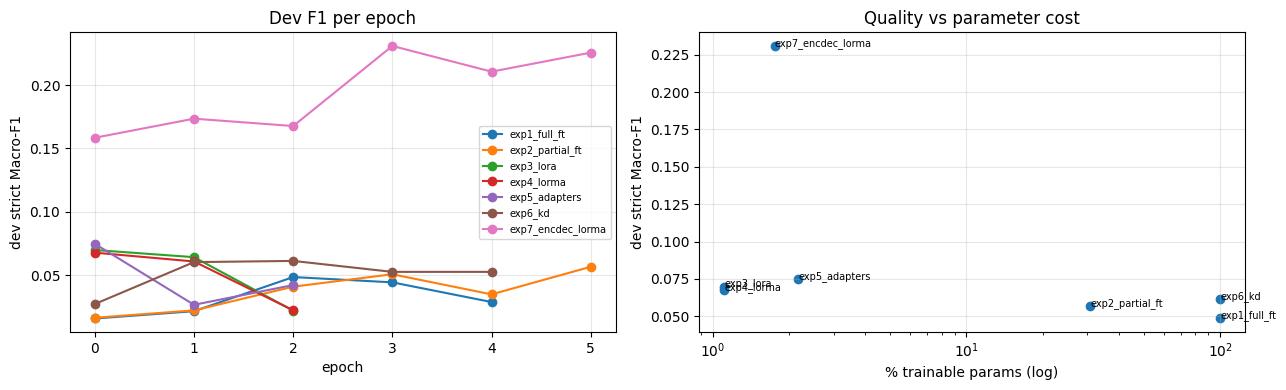

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

R = load_results()
df = pd.DataFrame([dict(experiment=k, **{c: v[c] for c in ["technique", "dev_f1", "dev_p", "dev_r", "dev_f1_viterbi",
                   "dev_f1_argmax", "trainable_params", "total_params", "peak_mem_gb", "train_time_s",
                   "dev_infer_time_s", "best_epoch"]}) for k, v in R.items()])
df["trainable_%"] = (100 * df.trainable_params / df.total_params).round(2)
df["total_M"] = (df.total_params / 1e6).round(1)
df = df.sort_values("dev_f1", ascending=False).reset_index(drop=True)
df.to_csv(os.path.join(PHASE2_DIR, "phase2_encdec_results.csv"), index=False)
display(df[["experiment", "technique", "dev_f1", "dev_p", "dev_r", "dev_f1_viterbi", "dev_f1_argmax",
            "total_M", "trainable_%", "peak_mem_gb", "train_time_s", "dev_infer_time_s"]])

per_label = pd.DataFrame({k: v["per_label_f1"] for k, v in R.items()})
display(per_label.style.background_gradient(axis=None, cmap="Blues").format("{:.3f}"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, v in R.items():
    h = pd.DataFrame(v["history"]); ax[0].plot(h.epoch, h.dev_f1, marker="o", label=k)
ax[0].set(xlabel="epoch", ylabel="dev strict Macro-F1", title="Dev F1 per epoch"); ax[0].legend(fontsize=7); ax[0].grid(alpha=.3)
ax[1].scatter(df["trainable_%"], df.dev_f1)
for _, r in df.iterrows(): ax[1].annotate(r.experiment, (r["trainable_%"], r.dev_f1), fontsize=7)
ax[1].set(xscale="log", xlabel="% trainable params (log)", ylabel="dev strict Macro-F1", title="Quality vs parameter cost")
ax[1].grid(alpha=.3); plt.tight_layout(); plt.savefig(os.path.join(PHASE2_DIR, "phase2_encdec_plots.png"), dpi=150); plt.show()

## 13. Error analysis on the best experiment
The brief asks about boundary errors, confusion between similar entity types (APP/RESP, A.COUNSEL/R.COUNSEL, COURT/AUTH, …),
boilerplate false positives, and long-document effects.

In [ ]:
def rebuild(name):
    m = EXPERIMENTS[name]["build"]()
    m.load_state_dict(torch.load(os.path.join(CKPT_DIR, f"{name}.pt"), map_location="cpu"), strict=False)
    return m.to(DEVICE).eval()

BEST = df.iloc[0].experiment
model = rebuild(BEST)
ev = evaluate(model)[DECODE]
cats, conf, examples = error_analysis(ev["pred"], dev_docs)
print(f"Best: {BEST}  dev strict Macro-F1 = {ev['f1']:.4f}\n")
print("Error categories:", dict(cats))
print("\nTop type confusions (gold -> pred):")
for (g, p), c in conf.most_common(10): print(f"  {g:10s} -> {p:10s} {c}")
print("\nRecall by position in document:", recall_by_position(ev["pred"], dev_docs))
for c, exs in examples.items():
    print(f"\n[{c}]")
    for e in exs: print("   ", e)
del model; free()

## 14. `prediction.json` + `submission.zip` for every experiment
Each experiment gets its own zip, with `prediction.json` at the **zip root**. The file is validated before zipping
(every test ID present, no unknown IDs, integer offsets inside the text, valid labels). Submit each zip separately on Codabench.

In [ ]:
def validate_prediction(pred, docs):
    assert set(pred) == set(docs), "test ID mismatch"
    for i, spans in pred.items():
        L = len(docs[i].text)
        for s, e, l in spans:
            assert isinstance(s, int) and isinstance(e, int) and 0 <= s < e <= L, (i, s, e)
            assert l in ENTITY_LABELS, l
    return True

def make_submission(name, method=DECODE):
    model = rebuild(name)
    probs = predict_word_probs(model, test_loader, test_docs)
    pred = {i: [[int(s), int(e), l] for (s, e, l) in decode_doc(test_docs[i], probs[i], method)] for i in test_docs}
    validate_prediction(pred, test_docs)
    out = os.path.join(SUB_DIR, name); os.makedirs(out, exist_ok=True)
    pj = os.path.join(out, "prediction.json")
    with open(pj, "w", encoding="utf-8") as f: json.dump(pred, f, ensure_ascii=False)
    zp = os.path.join(SUB_DIR, f"submission_{name}.zip")
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z: z.write(pj, arcname="prediction.json")
    with zipfile.ZipFile(zp) as z: assert z.namelist() == ["prediction.json"]
    print(f"{name}: {sum(map(len, pred.values())):,} spans over {len(pred)} docs -> {zp}")
    del model; free()
    return zp

for name in load_results():
    make_submission(name)

### Optional: refit the best recipe on fold1 + fold2 before the final submission
Model selection used the dev split. Once you have chosen a recipe, retrain it on **all** labelled documents for the
best number of epochs and submit that version too. (Its dev score is no longer a held-out estimate, so report the
earlier numbers.)

In [ ]:
REFIT = None   # e.g. "exp1_full_ft"
if REFIT:
    all_docs = prepare(ALL_LABELED_RAW, "all")
    all_loader = make_loader(all_docs, shuffle=True)
    n_ep = load_results()[REFIT]["best_epoch"] + 1
    cfg = EXPERIMENTS[REFIT]
    EXPERIMENTS[REFIT + "_refit"] = cfg
    seed_everything(); m = cfg["build"]()
    m, _ = train_experiment(REFIT + "_refit", m, cfg["technique"] + " (refit fold1+2)", cfg["lr"],
                            epochs=n_ep, train_loader_=all_loader)
    del m; free()
    make_submission(REFIT + "_refit")

## 15. Checklist and analysis prompts
- [ ] ≥ 6 Codabench submissions with *methodologically different* techniques (exp1–6). LoRMA is in (exp4), and KD is in (exp6).
- [ ] Across your whole Phase 2, all four Phase-1 architectures are used. This notebook covers the encoder–decoder; the GQLA notebook covers another.
- [ ] Every zip has `prediction.json` at its root and passes `validate_prediction`.
- [ ] LLM-use declaration updated, and LoRMA [12], LoRA [3], Houlsby [6] and Hinton KD [2] cited.

**Points to cover in the report (from brief §8.5), with where the evidence comes from:**
1. Best technique and how close PEFT gets to full FT → `df` (dev_f1 vs trainable_%).
2. LoRA vs LoRMA⁺ at the same rank: additive vs multiplicative updates (and convergence speed, from `history`).
3. Span modelling → alignment ceiling (§5) and Viterbi vs argmax (`dev_f1_viterbi` vs `dev_f1_argmax`).
4. Hard entity types and boundaries → per-label table, `wrong_type` confusions, `boundary` examples.
5. Class imbalance → rerun one recipe with `CLASS_WEIGHTING="sqrt_inv"` and compare rare-label F1.
6. Long documents → `recall_by_position`; try `STRIDE` 256 vs 448.
7. KD → student params / inference time / peak memory vs teacher, and the F1 gap.
8. Does the decoder help? → exp7 vs exp4 (same PEFT method; encoder-only vs encoder+decoder head).
9. Phase-1 transfer → optionally train `build_full_ft` with randomly initialised weights as a no-pretraining baseline.